# RakshPulse: PPG waveform exploration

Run after `python -m rakshpulse.data.build guilin_dualwave foggia_multiwave ppg_bp`.
This notebook looks at raw versus processed red/IR PPG, the signal-quality gate, and how pulse shape relates to BP in the Guilin cohort. **Fingertip-type data only. Not behind-ear.**

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
from rakshpulse.data.dataset_loader import iter_guilin
from rakshpulse.data.build import PROCESSED
from rakshpulse.features.feature_pipeline import extract_features
from rakshpulse.preprocessing.segmentation import detect_peaks

## 1. One raw recording (subject 001, rest)

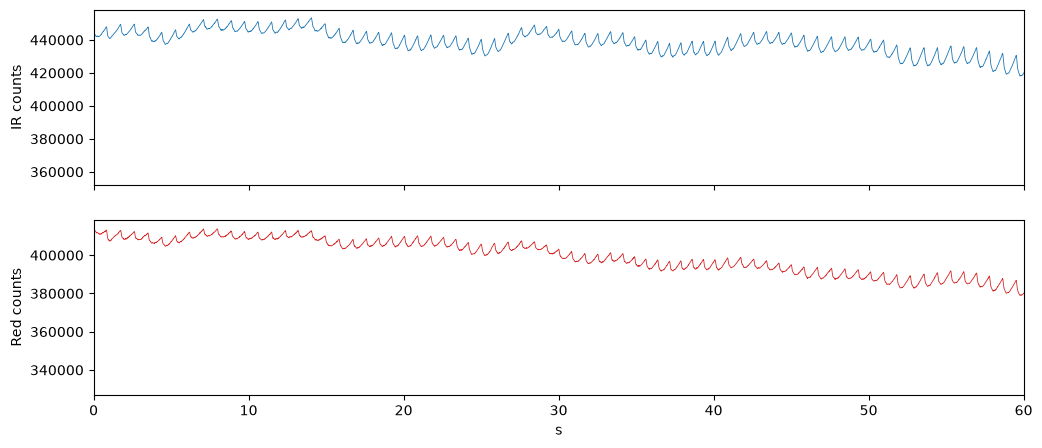

In [2]:
rec = next(iter_guilin())
t = np.arange(rec.channels['ir'].size) / rec.fs
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(t, rec.channels['ir'], lw=.6); ax[0].set_ylabel('IR counts')
ax[1].plot(t, rec.channels['red'], lw=.6, color='C3'); ax[1].set_ylabel('Red counts'); ax[1].set_xlabel('s')
ax[0].set_xlim(0, 60);

## 2. A 10 s window after preprocessing, with detected beats and the SQI result

{'ir_sys_ratio': 0.268,
 'ir_w50': 0.485,
 'ir_hr': 78.947,
 'red_ir_corr': 0.997,
 'ratio_of_ratios': 0.678}

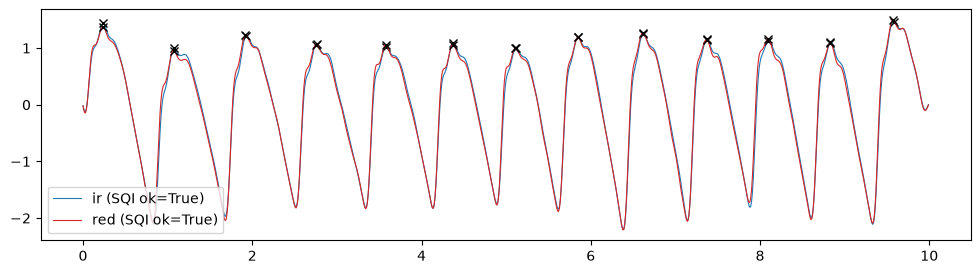

In [3]:
a = int(30 * rec.fs); w = {c: rec.channels[c][a:a + int(10 * rec.fs)] for c in ('ir', 'red')}
feats, proc = extract_features(w, rec.fs)
fig, ax = plt.subplots(figsize=(12, 3))
for c, col in (('ir', 'C0'), ('red', 'C3')):
    z = proc[c].filtered; pk = detect_peaks(z, 100)
    ax.plot(np.arange(z.size) / 100, z, col, lw=.8, label=f"{c} (SQI ok={proc[c].sqi.acceptable})")
    ax.plot(pk / 100, z[pk], 'kx')
ax.legend();
{k: round(v, 3) for k, v in feats.items() if k in ('ir_hr', 'ir_sys_ratio', 'ir_w50', 'red_ir_corr', 'ratio_of_ratios')}

## 3. SQI pass rates and rejection reasons across the cohort

In [4]:
f = pd.read_csv(PROCESSED / 'guilin_dualwave_features.csv')
print(f[['ir_sqi_ok', 'red_sqi_ok']].mean())
f.loc[~f.ir_sqi_ok, 'ir_sqi_reasons'].str.split('|').explode().value_counts()

ir_sqi_ok     0.966153
red_sqi_ok    0.933522
dtype: float64


ir_sqi_reasons
low_template_correlation    131
too_few_beats                57
low_cardiac_power            32
irregular_beat_intervals     26
implausible_heart_rate       11
Name: count, dtype: int64

## 4. How strongly do single features relate to BP? (subject level, Spearman)
A weak correlation for every feature is consistent with the modelling results: on this narrow-BP young cohort, PPG morphology carries little BP information.

In [5]:
subj = f[f.ir_sqi_ok & f.red_sqi_ok].groupby('subject_id').median(numeric_only=True)
cols = [c for c in subj.columns if c.startswith(('ir_', 'red_')) and not c.startswith(('ir_sqi', 'red_sqi', 'ir_n_', 'red_n_', 'ir_perf', 'red_perf'))]
corr = subj[cols + ['sbp', 'dbp', 'demo_age', 'demo_sex']].corr(method='spearman')[['sbp', 'dbp']].drop(['sbp', 'dbp'])
corr.reindex(corr.sbp.abs().sort_values(ascending=False).index).head(15).round(2)

,sbp,dbp
demo_sex,0.45,0.17
red_w25,-0.23,-0.13
red_beat_T,-0.23,-0.19
red_w10,-0.23,-0.17
ir_beat_T,-0.22,-0.19
ir_hr,0.22,0.19
red_f0,0.22,0.19
red_hr,0.21,0.18
red_w50,-0.21,-0.09
ir_w25,-0.21,-0.14


## 5. Ensemble beat by SBP tertile

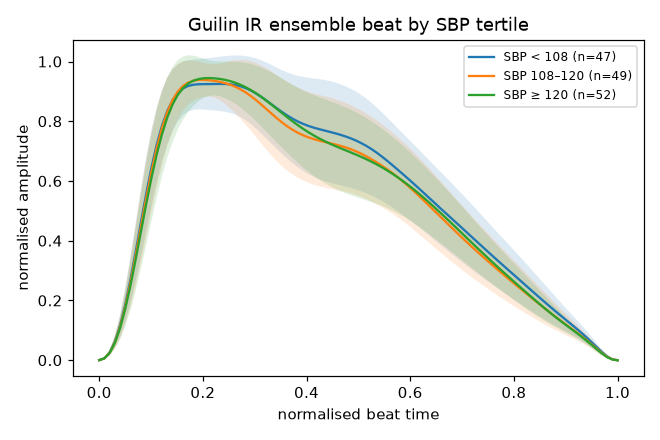

In [6]:
from IPython.display import Image
Image('../docs/figures/mean_beat_by_sbp_tertile.png')